# Final Project Environmental Factors
**Business 35137 — Winter 2026**

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [10]:
DATA_DIR = '../Data/'
RAW_DIR  = os.path.join(DATA_DIR, 'Prec.Temp Raw Data/')
OUT_DIR  = os.path.join(DATA_DIR, 'Intermediate/')
os.makedirs(OUT_DIR, exist_ok=True)

PREC_FILE = os.path.join(RAW_DIR, 'climdiv-pcpncy-v1.0.0-20260205')
TEMP_FILE = os.path.join(RAW_DIR, 'climdiv-tmpccy-v1.0.0-20260205')

In [11]:
# ── NOAA nClimDiv Fixed-Width Parser ──────────────────────────────────────────
# Format (1-indexed per README):
#   cols  1- 2 : State code (01–50)   <- NOAA-specific, NOT standard FIPS
#   cols  3- 5 : County FIPS 3-digit (001–999)
#   cols  6- 7 : Element code (01=Precip, 02=AvgTemp)
#   cols  8-11 : Year
#   cols 12-18 : Jan value (f7.2)  ... 7 chars x 12 months -> cols 89-95 for Dec

# NOAA codes run 01-50 in strict alphabetical order (Hawaii=49, Alaska=50).
# Standard Federal FIPS codes have gaps and a different ordering.
# This mapping is required to build a valid geo_id that joins to external databases.
NOAA_TO_STATE_FIPS = {
    '01': '01',  # Alabama
    '02': '04',  # Arizona
    '03': '05',  # Arkansas
    '04': '06',  # California
    '05': '08',  # Colorado
    '06': '09',  # Connecticut
    '07': '10',  # Delaware
    '08': '12',  # Florida
    '09': '13',  # Georgia
    '10': '16',  # Idaho
    '11': '17',  # Illinois
    '12': '18',  # Indiana
    '13': '19',  # Iowa
    '14': '20',  # Kansas
    '15': '21',  # Kentucky
    '16': '22',  # Louisiana
    '17': '23',  # Maine
    '18': '24',  # Maryland
    '19': '25',  # Massachusetts
    '20': '26',  # Michigan
    '21': '27',  # Minnesota
    '22': '28',  # Mississippi
    '23': '29',  # Missouri
    '24': '30',  # Montana
    '25': '31',  # Nebraska
    '26': '32',  # Nevada
    '27': '33',  # New Hampshire
    '28': '34',  # New Jersey
    '29': '35',  # New Mexico
    '30': '36',  # New York
    '31': '37',  # North Carolina
    '32': '38',  # North Dakota
    '33': '39',  # Ohio
    '34': '40',  # Oklahoma
    '35': '41',  # Oregon
    '36': '42',  # Pennsylvania
    '37': '44',  # Rhode Island
    '38': '45',  # South Carolina
    '39': '46',  # South Dakota
    '40': '47',  # Tennessee
    '41': '48',  # Texas
    '42': '49',  # Utah
    '43': '50',  # Vermont
    '44': '51',  # Virginia
    '45': '53',  # Washington
    '46': '54',  # West Virginia
    '47': '55',  # Wisconsin
    '48': '56',  # Wyoming
    '49': '15',  # Hawaii
    '50': '02',  # Alaska
}

MONTHS   = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
COLSPECS = ([(0,2),(2,5),(5,7),(7,11)]
            + [(11 + i*7, 18 + i*7) for i in range(12)])
COLNAMES = ['state','county3','element','year'] + MONTHS

def parse_noaa_county(filepath, missing_sentinel):
    """
    Parse NOAA nClimDiv county fixed-width file -> long-format DataFrame.

    Returns
    -------
    DataFrame: geo_id | year | month | month_num | value
      geo_id = standard 5-digit FIPS (correct state FIPS + county 3-digit FIPS)
    """
    df = pd.read_fwf(
        filepath, colspecs=COLSPECS, header=None, names=COLNAMES,
        dtype={'state':'str','county3':'str','element':'str','year':int}
    )

    # Map NOAA state code -> standard Federal FIPS state code
    state_fips = df['state'].str.zfill(2).map(NOAA_TO_STATE_FIPS)
    n_unmapped = state_fips.isna().sum()
    if n_unmapped > 0:
        unmapped = df.loc[state_fips.isna(), 'state'].unique().tolist()
        print(f"  Dropping {n_unmapped:,} rows with unmapped NOAA state codes: {unmapped}")

    df['geo_id'] = state_fips + df['county3'].str.zfill(3)
    df = df.dropna(subset=['geo_id'])

    # Wide -> long (one row per county-year-month)
    df = (df[['geo_id','year'] + MONTHS]
            .melt(id_vars=['geo_id','year'], value_vars=MONTHS,
                  var_name='month', value_name='value'))

    # Month number 1-12
    month_map = {m: i+1 for i, m in enumerate(MONTHS)}
    df['month_num'] = df['month'].map(month_map)

    # Mask missing-value sentinels
    df.loc[df['value'] <= missing_sentinel, 'value'] = np.nan

    # Verify no duplicate (geo_id, year, month) keys
    dupes = df.duplicated(['geo_id','year','month']).sum()
    if dupes > 0:
        print(f"  WARNING: {dupes:,} duplicate (geo_id, year, month) rows dropped")
        df = df.drop_duplicates(['geo_id','year','month'])

    return df[['geo_id','year','month','month_num','value']].reset_index(drop=True)

In [12]:
# ── Load Raw Data ──────────────────────────────────────────────────────────────
print("Loading precipitation...")
prec = parse_noaa_county(PREC_FILE, missing_sentinel=-9.0)

print("Loading temperature...")
temp = parse_noaa_county(TEMP_FILE, missing_sentinel=-99.0)

print(f"\nPrecip : {len(prec):>10,} rows  |  {prec['geo_id'].nunique():,} counties")
print(f"Temp   : {len(temp):>10,} rows  |  {temp['geo_id'].nunique():,} counties")
print(f"\nYear range: {prec['year'].min()} - {prec['year'].max()}")
prec.head()

Loading precipitation...
Loading temperature...

Precip :  4,960,368 rows  |  3,142 counties
Temp   :  4,960,368 rows  |  3,142 counties

Year range: 1895 - 2026


,geo_id,year,month,month_num,value
0,01001,1895,Jan,1,7.03
1,01001,1896,Jan,1,5.86
2,01001,1897,Jan,1,3.27
3,01001,1898,Jan,1,2.33
4,01001,1899,Jan,1,5.80


In [13]:
# ── Create County-Month Identifier ────────────────────────────────────────────
# Each county gets a separate baseline per calendar month.
# e.g. '48113_Jul' = Dallas County TX, July only — compared across all years.
# ~132 observations per group (one per year), vs ~396 under the season approach.

for df in [prec, temp]:
    df['county_month'] = df['geo_id'] + '_' + df['month']

print('Unique county-month groups :', prec['county_month'].nunique())
print('Avg observations per group :', round(prec['value'].notna().sum() / prec['county_month'].nunique(), 1))
prec[['geo_id','year','month','county_month']].head(8)

Unique county-month groups : 37704
Avg observations per group : 130.6


,geo_id,year,month,county_month
0,01001,1895,Jan,01001_Jan
1,01001,1896,Jan,01001_Jan
2,01001,1897,Jan,01001_Jan
3,01001,1898,Jan,01001_Jan
4,01001,1899,Jan,01001_Jan
5,01001,1900,Jan,01001_Jan
6,01001,1901,Jan,01001_Jan
7,01001,1902,Jan,01001_Jan


In [14]:
# ── Compute Z-Scores and Directional Anomaly Flags ────────────────────────────
# For each (county, month) pair:
#   cm_mean = mean of all non-missing values for that county-month across all years
#   cm_std  = std  of all non-missing values for that county-month across all years
#   z_score = (value - cm_mean) / cm_std
#   anomaly = 'above' if z > +2  |  'below' if z < -2  |  None if normal

def add_zscore_flag(df):
    stats = (
        df.dropna(subset=['value'])
          .groupby('county_month')['value']
          .agg(cm_mean='mean', cm_std='std')
          .reset_index()
    )
    df = df.merge(stats, on='county_month', how='left')
    df['z_score'] = (df['value'] - df['cm_mean']) / df['cm_std']
    df['anomaly'] = np.where(df['z_score'] >  2, 'above',
                    np.where(df['z_score'] < -2, 'below', None))
    return df

prec = add_zscore_flag(prec)
temp = add_zscore_flag(temp)

for label, df in [('Precipitation', prec), ('Temperature', temp)]:
    above = (df['anomaly'] == 'above').sum()
    below = (df['anomaly'] == 'below').sum()
    total = df['value'].notna().sum()
    print(f"{label}: {above:,} above ({above/total*100:.2f}%)  |  {below:,} below ({below/total*100:.2f}%)")

prec[['geo_id','year','month','county_month','value','cm_mean','cm_std','z_score','anomaly']].head(8)

Precipitation: 214,394 above (4.35%)  |  3,397 below (0.07%)
Temperature: 108,597 above (2.20%)  |  110,469 below (2.24%)


,geo_id,year,month,county_month,value,cm_mean,cm_std,z_score,anomaly
0,01001,1895,Jan,01001_Jan,7.03,5.079015,2.357702,0.827494,NaN
1,01001,1896,Jan,01001_Jan,5.86,5.079015,2.357702,0.331248,NaN
2,01001,1897,Jan,01001_Jan,3.27,5.079015,2.357702,-0.767279,NaN
3,01001,1898,Jan,01001_Jan,2.33,5.079015,2.357702,-1.165972,NaN
4,01001,1899,Jan,01001_Jan,5.80,5.079015,2.357702,0.305800,NaN
5,01001,1900,Jan,01001_Jan,3.18,5.079015,2.357702,-0.805452,NaN
6,01001,1901,Jan,01001_Jan,5.20,5.079015,2.357702,0.051315,NaN
7,01001,1902,Jan,01001_Jan,4.24,5.079015,2.357702,-0.355861,NaN


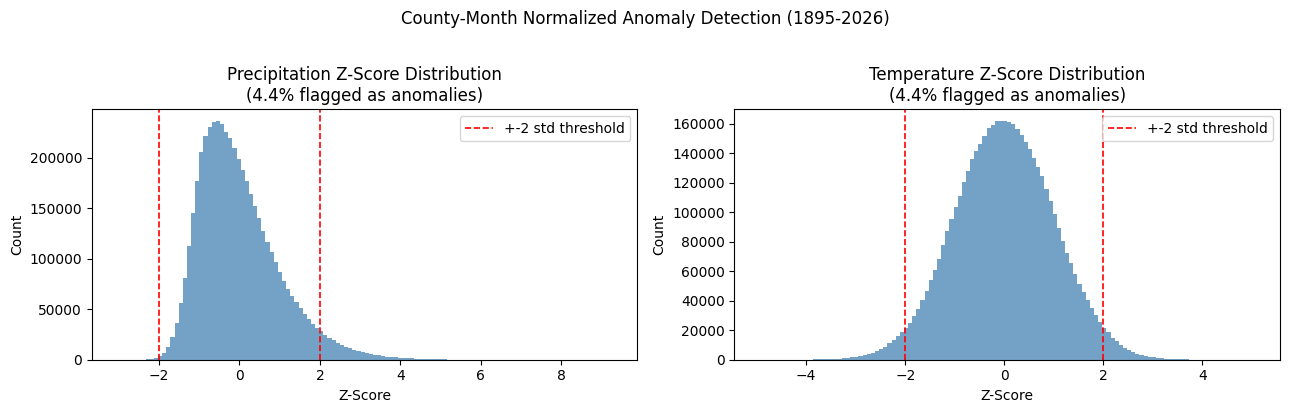

In [15]:
# ── Sanity Check: Z-Score Distributions ───────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, df, label in zip(axes, [prec, temp], ['Precipitation', 'Temperature']):
    z = df['z_score'].dropna()
    flag_pct = (df['anomaly'].isin(['above','below'])).mean() * 100
    ax.hist(z, bins=120, color='steelblue', alpha=0.75, edgecolor='none')
    ax.axvline(-2, color='red', linestyle='--', linewidth=1.2, label='+-2 std threshold')
    ax.axvline( 2, color='red', linestyle='--', linewidth=1.2)
    ax.set_title(f'{label} Z-Score Distribution\n({flag_pct:.1f}% flagged as anomalies)')
    ax.set_xlabel('Z-Score')
    ax.set_ylabel('Count')
    ax.legend()

plt.suptitle('County-Month Normalized Anomaly Detection (1895-2026)', y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

In [16]:
# ── Merge Precipitation + Temperature -> Single Panel ─────────────────────────
PREC_COLS = {'value':'Precipitation_Inches', 'cm_mean':'prec_cm_mean',
             'cm_std':'prec_cm_std', 'z_score':'prec_z', 'anomaly':'prec_anomaly'}
TEMP_COLS = {'value':'Avg_Temp_F', 'cm_mean':'temp_cm_mean',
             'cm_std':'temp_cm_std', 'z_score':'temp_z', 'anomaly':'temp_anomaly'}

IDX = ['geo_id', 'year', 'month_num']

prec_idx = (prec[['geo_id','year','month','month_num','county_month',
                   'value','cm_mean','cm_std','z_score','anomaly']]
            .rename(columns=PREC_COLS)
            .set_index(IDX))

temp_idx = (temp[['geo_id','year','month_num',
                   'value','cm_mean','cm_std','z_score','anomaly']]
            .rename(columns=TEMP_COLS)
            .set_index(IDX))

panel = pd.concat([prec_idx, temp_idx], axis=1).reset_index()

print(f"Merged panel: {len(panel):,} rows  |  {panel['geo_id'].nunique():,} counties")
print(f"Columns: {list(panel.columns)}")
panel.head(6)

# ── Save Outputs ───────────────────────────────────────────────────────────────
prec_out  = os.path.join(OUT_DIR, 'prec_county_anomaly.parquet')
temp_out  = os.path.join(OUT_DIR, 'temp_county_anomaly.parquet')
panel_out = os.path.join(OUT_DIR, 'weather_panel.parquet')

prec.to_parquet(prec_out,   index=False)
temp.to_parquet(temp_out,   index=False)
panel.to_parquet(panel_out, index=False)

print(f"\nSaved -> {prec_out}")
print(f"Saved -> {temp_out}")
print(f"Saved -> {panel_out}")

print("\nprec_county_anomaly.parquet columns:")
print(list(pd.read_parquet(prec_out).columns))
print("\ntemp_county_anomaly.parquet columns:")
print(list(pd.read_parquet(temp_out).columns))
print("\nweather_panel.parquet columns:")
print(list(pd.read_parquet(panel_out).columns))

Merged panel: 4,960,368 rows  |  3,142 counties
Columns: ['geo_id', 'year', 'month_num', 'month', 'county_month', 'Precipitation_Inches', 'prec_cm_mean', 'prec_cm_std', 'prec_z', 'prec_anomaly', 'Avg_Temp_F', 'temp_cm_mean', 'temp_cm_std', 'temp_z', 'temp_anomaly']

Saved -> ../Data/Intermediate/prec_county_anomaly.parquet
Saved -> ../Data/Intermediate/temp_county_anomaly.parquet
Saved -> ../Data/Intermediate/weather_panel.parquet

prec_county_anomaly.parquet columns:
['geo_id', 'year', 'month', 'month_num', 'value', 'county_month', 'cm_mean', 'cm_std', 'z_score', 'anomaly']

temp_county_anomaly.parquet columns:
['geo_id', 'year', 'month', 'month_num', 'value', 'county_month', 'cm_mean', 'cm_std', 'z_score', 'anomaly']

weather_panel.parquet columns:
['geo_id', 'year', 'month_num', 'month', 'county_month', 'Precipitation_Inches', 'prec_cm_mean', 'prec_cm_std', 'prec_z', 'prec_anomaly', 'Avg_Temp_F', 'temp_cm_mean', 'temp_cm_std', 'temp_z', 'temp_anomaly']
